# JONSWAP Spectral Verification

This notebook verifies that the `IrregularWave_JONSWAP` realisation reproduces the target JONSWAP energy spectrum. The strategy follows the standard oceanographic practice of **segment averaging** (Welch's method) to reduce the variance of the raw periodogram:

1. **Generate** a 3-hour surface elevation time series from a JONSWAP sea state.
2. **Compute the PSD** by two routes:
   - *Fixed-segment averaging* — chop the record into N equal non-overlapping segments, compute a periodogram for each, then average. Shows how variance decreases with more segments.
   - *Welch's method* — same segment length but with 50 % overlap and a Hanning window, squeezing more averages from the same record.
3. **Compare** both estimates with the theoretical JONSWAP spectrum.

**Wave parameters:** Hs = 3 m, Tp = 10 s, d = 30 m, γ = 3.3  
**Time series:** T = 3 h, Δt = 0.5 s → 21 600 samples, f_Nyquist = 1 Hz

## 1 · Imports

In [1]:
import sys
sys.path.insert(0, '../src')

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from wave_tank import IrregularWave_JONSWAP
from spectrum import jonswap, periodogram, avg_periodogram, welch_psd

os.makedirs('../output', exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 15,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 18,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

## 2 · Wave generation

In [2]:
# ── Wave parameters ────────────────────────────────────────────────────────────
Hs    = 3.0    # significant wave height [m]
Tp    = 10.0   # peak period [s]
d     = 30.0   # water depth [m]
gamma = 3.3    # JONSWAP peak enhancement factor

# ── Time-series parameters ─────────────────────────────────────────────────────
dt      = 0.5          # time step [s]
T_total = 3 * 3600     # 3 hours [s]
t       = np.arange(0, T_total, dt)

# ── Build wave object ──────────────────────────────────────────────────────────
# T_repeat = T_total ensures the wave component frequencies Δf = 1/T_total
# align exactly with the FFT bin spacing of the full record.
wave = IrregularWave_JONSWAP(
    Hs=Hs, Tp=Tp, d=d, gamma=gamma,
    T_repeat=T_total, seed=42
)
print(wave)
print(f"\nNumber of wave components : {len(wave.f):,}")
print(f"Frequency resolution      : Δf = {wave.f[1]-wave.f[0]:.5f} Hz")
print(f"Number of time steps      : {len(t):,}")

IrregularWave_JONSWAP(Hs=3.0m, Tp=10.0s, d=30.0m, gamma=3.3, N=4860 components, actual_hs=3.062m)

Number of wave components : 4,860
Frequency resolution      : Δf = 0.00009 Hz
Number of time steps      : 21,600


### Evaluate surface elevation (chunked to manage memory)

With 4 860 components and 21 600 time steps the naïve broadcast would allocate an ~840 MB intermediate array. Evaluating in chunks of 2 000 time steps keeps peak memory below 80 MB.

In [3]:
def compute_eta(wave, t, x=0.0, chunk=2000):
    """Evaluate surface elevation in time chunks: O(N_comp × chunk) memory."""
    eta = np.empty(len(t))
    k_col     = wave.k[:, None]       # (N_comp, 1)
    omega_col = wave.omega[:, None]   # (N_comp, 1)          
    phi_col   = wave.phases[:, None]  # (N_comp, 1)
    for i in range(0, len(t), chunk):
        t_c = t[i:i + chunk][None, :]                    # (1, chunk)
        phase = k_col * x - omega_col * t_c + phi_col   # (N_comp, chunk)
        eta[i:i + chunk] = wave.amplitudes @ np.cos(phase)
    return eta

print("Evaluating \u03b7(t) ...")
eta = compute_eta(wave, t)
print(f"Done. \u03b7 shape = {eta.shape}")
print(f"\u03c3 = {eta.std():.3f} m   (expect ≈ Hs/4 = {Hs/4:.3f} m)")
print(f"Realised Hs = 4\u03c3 = {4*eta.std():.3f} m   (target {Hs} m)")

Evaluating η(t) ...
Done. η shape = (21600,)
σ = 0.765 m   (expect ≈ Hs/4 = 0.750 m)
Realised Hs = 4σ = 3.062 m   (target 3.0 m)


## 3 · Time-series overview

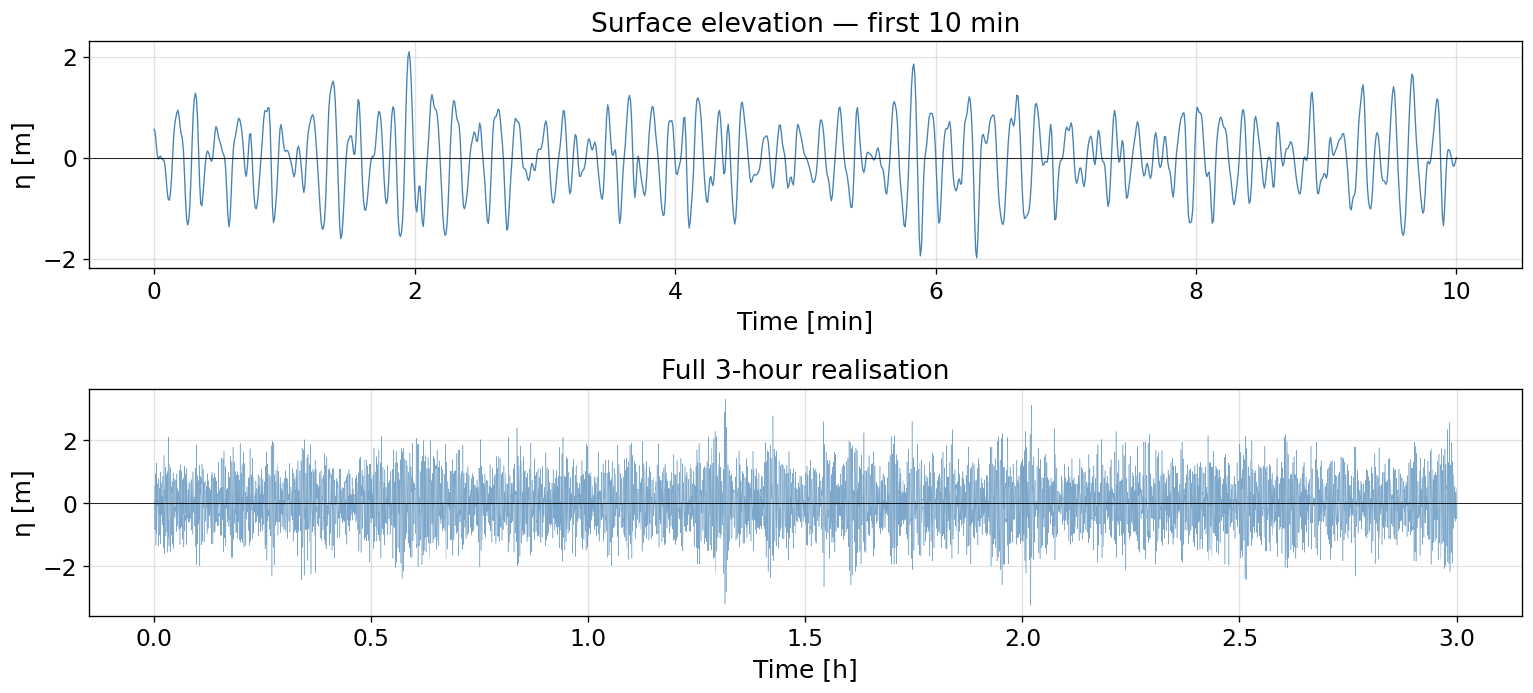

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=False)

ax = axes[0]
m10 = t <= 600
ax.plot(t[m10] / 60, eta[m10], lw=0.8, color='steelblue')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('Time [min]')
ax.set_ylabel('η [m]')
ax.set_title('Surface elevation — first 10 min')

ax = axes[1]
ax.plot(t / 3600, eta, lw=0.3, color='steelblue', alpha=0.7)
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('Time [h]')
ax.set_ylabel('η [m]')
ax.set_title('Full 3-hour realisation')

plt.tight_layout()
fig.savefig('../output/jonswap_timeseries.pdf', bbox_inches='tight')
plt.show()

## 4 · Spectral estimation tools

### 4.1 Target JONSWAP spectrum

In [5]:
# Dense reference grid for plotting
f_ref = np.linspace(0.02, 0.55, 2000)
S_ref = jonswap(f_ref, Hs, Tp, gamma)

# Verify the target spectrum integrates to the correct variance
Hs_from_spec = 4 * np.sqrt(np.trapezoid(S_ref, f_ref))
print(f"∫S(f)df → Hs = {Hs_from_spec:.3f} m  (target {Hs} m)")

∫S(f)df → Hs = 3.002 m  (target 3.0 m)


### 4.2 Spectral estimation functions

`periodogram`, `avg_periodogram`, and `welch_psd` are imported from `src/spectrum.py`.

In [6]:
print("Spectral estimation functions ready: periodogram, avg_periodogram, welch_psd")

Spectral estimation functions ready: periodogram, avg_periodogram, welch_psd


## 5 · Raw periodogram — full 3-hour record

No averaging: every FFT bin is an independent sample of the spectrum. The estimate is **unbiased but very noisy** — the variance equals the square of the true spectrum at each frequency (chi-squared with 2 degrees of freedom).

Full record: N = 21,600 samples
Δf = 0.00009 Hz   (= 1/T_total)
f_Nyquist = 1.000 Hz
Hs from raw spectrum = 3.062 m


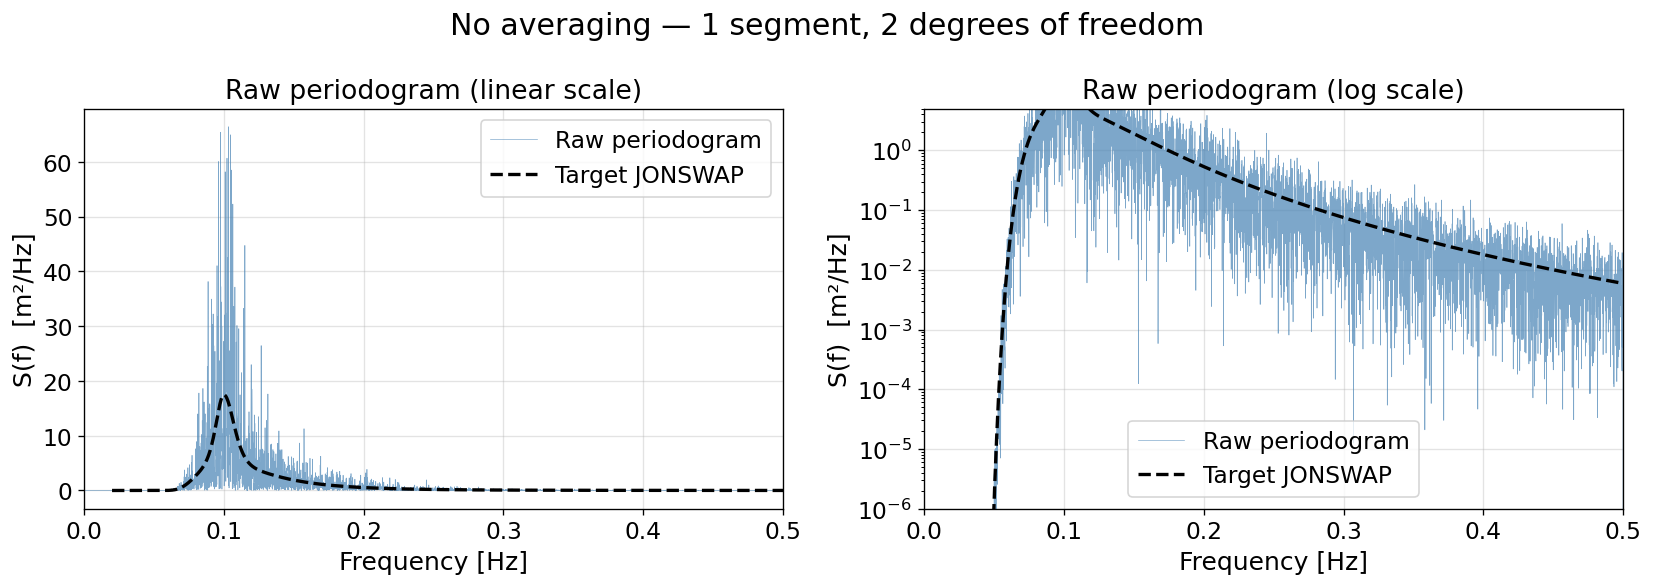

In [7]:
f_raw, S_raw = periodogram(eta, dt)
print(f"Full record: N = {len(eta):,} samples")
print(f"Δf = {f_raw[1]:.5f} Hz   (= 1/T_total)")
print(f"f_Nyquist = {f_raw[-1]:.3f} Hz")
Hs_raw = 4 * np.sqrt(np.trapezoid(S_raw[f_raw <= 0.55], f_raw[f_raw <= 0.55]))
print(f"Hs from raw spectrum = {Hs_raw:.3f} m")

fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(14, 5))

for ax, yscale in [(ax_lin, 'linear'), (ax_log, 'log')]:
    ax.plot(f_raw, S_raw, lw=0.4, color='steelblue', alpha=0.7, label='Raw periodogram')
    ax.plot(f_ref, S_ref, 'k--', lw=2, label='Target JONSWAP')
    ax.set_xlim(0, 0.5)
    ax.set_xlabel('Frequency [Hz]')
    ax.set_ylabel('S(f)  [m²/Hz]')
    ax.set_yscale(yscale)
    ax.legend()
    ax.set_title(f'Raw periodogram ({yscale} scale)')
    if yscale == 'log':
        ax.set_ylim(1e-6, 5)

fig.suptitle('No averaging — 1 segment, 2 degrees of freedom')
plt.tight_layout()
fig.savefig('../output/jonswap_raw_periodogram.pdf', bbox_inches='tight')
plt.show()

## 6 · Convergence of fixed-segment averaging

Splitting the record into **N** equal segments gives **2N degrees of freedom** (chi-squared). The variance of the estimate scales as 1/N, so the scatter halves each time we double the number of segments — at the cost of coarser frequency resolution (Δf grows by the same factor).

In [8]:
n_seg_list = [1, 4, 8, 12]
colors     = plt.cm.plasma(np.linspace(0.15, 0.85, len(n_seg_list)))

# Pre-compute all estimates and print a summary table
seg_results = {}
print(f"{'N segments':>12}  {'Seg length [s]':>16}  {'Δf [Hz]':>10}  {'DOF':>6}  {'Hs [m]':>8}")
print('-' * 60)
for n_seg in n_seg_list:
    f_e, S_e = avg_periodogram(eta, dt, n_seg)
    seg_results[n_seg] = (f_e, S_e)
    Ns     = len(eta) // n_seg
    df_seg = 1.0 / (Ns * dt)
    Hs_e   = 4 * np.sqrt(np.trapezoid(S_e[f_e <= 0.55], f_e[f_e <= 0.55]))
    print(f"{n_seg:>12}  {Ns * dt:>16.0f}  {df_seg:>10.5f}  {2*n_seg:>6}  {Hs_e:>8.3f}")

  N segments    Seg length [s]     Δf [Hz]     DOF    Hs [m]
------------------------------------------------------------
           1             10800     0.00009       2     3.062
           4              2700     0.00037       8     3.062
           8              1350     0.00074      16     3.062
          12               900     0.00111      24     3.062


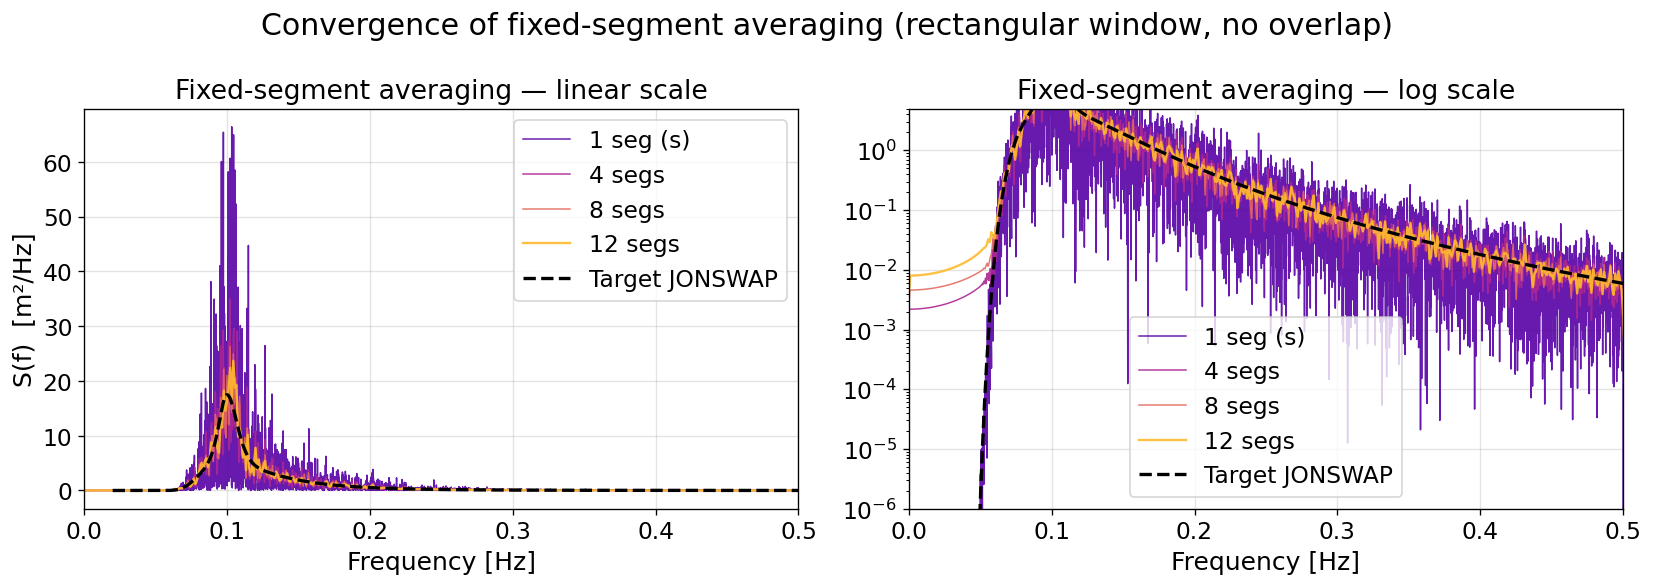

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, yscale in zip(axes, ['linear', 'log']):
    for n_seg, col in zip(n_seg_list, colors):
        f_e, S_e = seg_results[n_seg]
        lw = 1.4 if n_seg == n_seg_list[-1] else 0.9
        ax.plot(f_e, S_e, color=col, lw=lw, alpha=0.9,
                label=f'{n_seg} seg' + (' (s)' if n_seg == 1 else 's'))

    ax.plot(f_ref, S_ref, 'k--', lw=2, label='Target JONSWAP', zorder=5)
    ax.set_xlim(0, 0.5)
    ax.set_xlabel('Frequency [Hz]')
    ax.set_yscale(yscale)
    if yscale == 'log':
        ax.set_ylim(1e-6, 5)
    ax.legend()
    ax.set_title(f'Fixed-segment averaging — {yscale} scale')

axes[0].set_ylabel('S(f)  [m²/Hz]')
fig.suptitle('Convergence of fixed-segment averaging (rectangular window, no overlap)')
plt.tight_layout()
fig.savefig('../output/jonswap_fixed_segment.pdf', bbox_inches='tight')
plt.show()

### 6.1 · Stacked panel — one segment count per row

Arranging segments on separate rows makes it easier to judge the noise level at each stage.

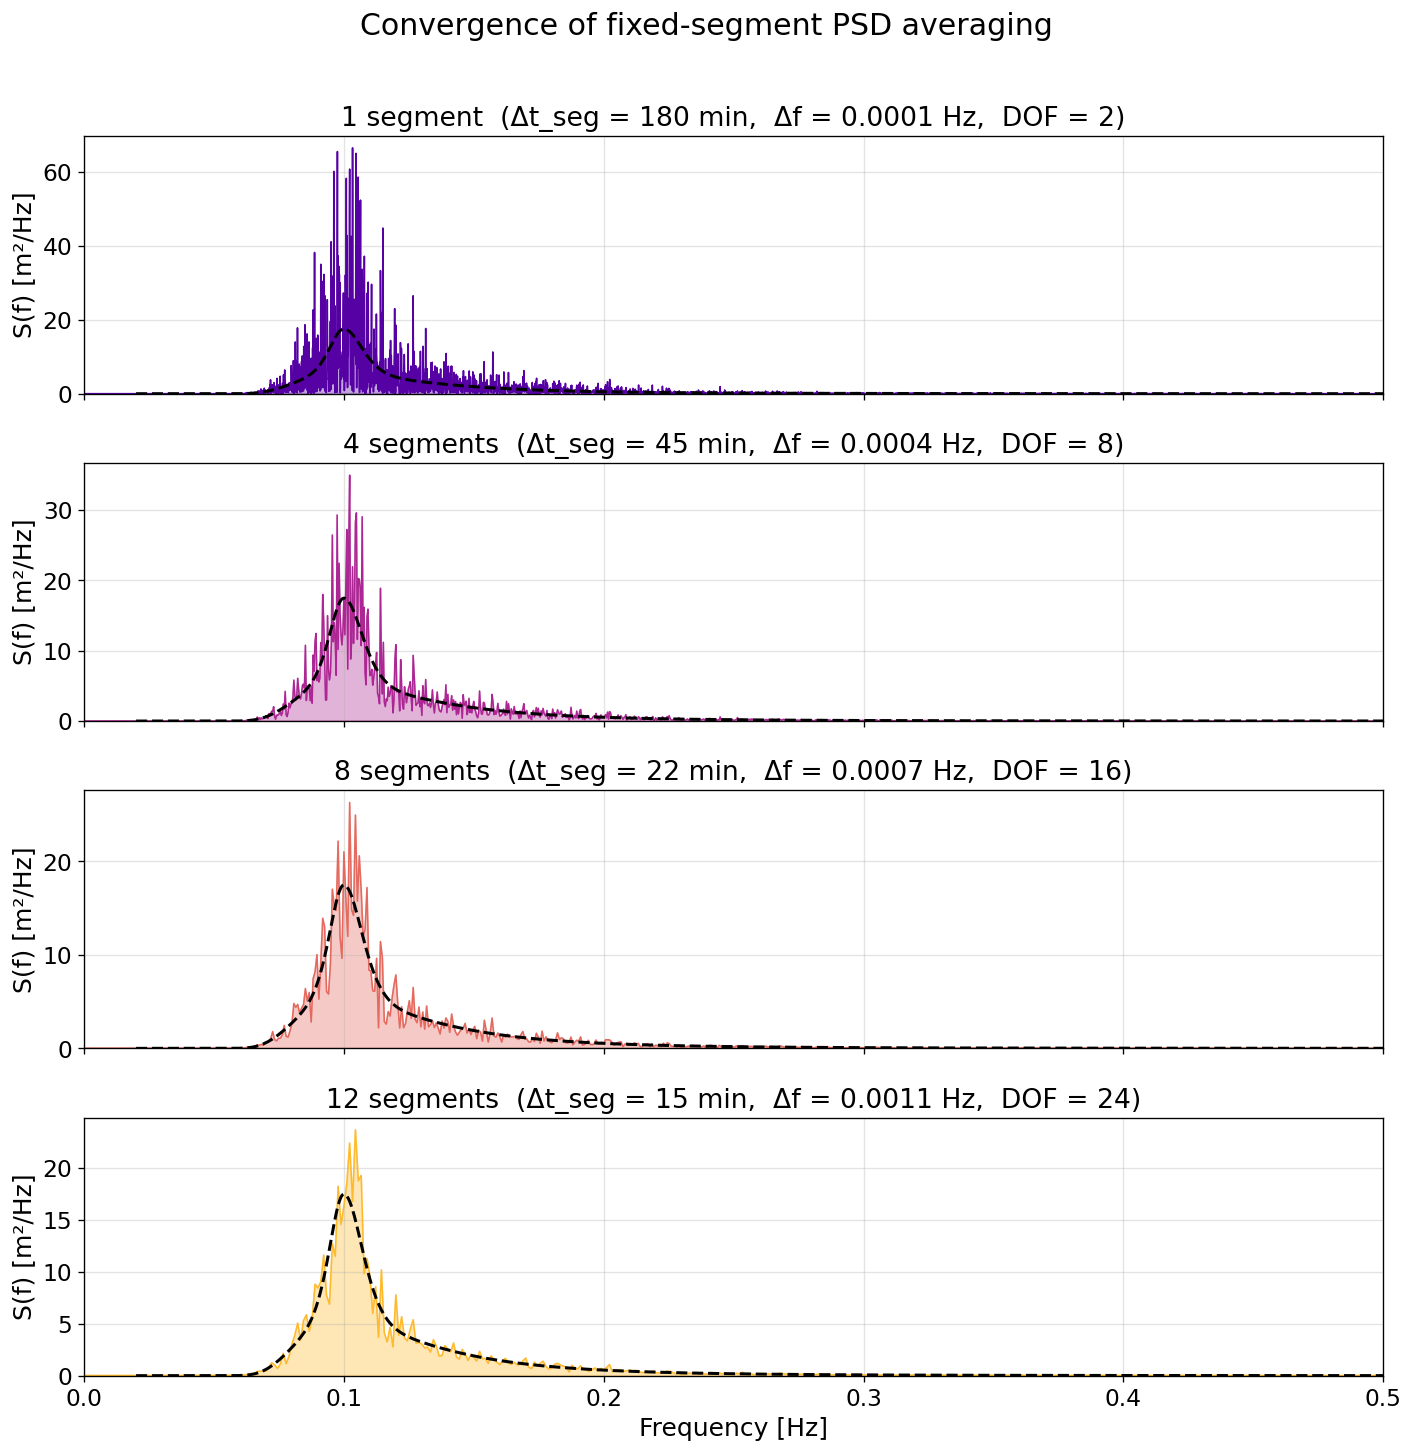

In [10]:
fig, axes = plt.subplots(len(n_seg_list), 1, figsize=(12, 12), sharex=True)

for ax, n_seg, col in zip(axes, n_seg_list, colors):
    f_e, S_e = seg_results[n_seg]
    ax.fill_between(f_e, S_e, alpha=0.35, color=col)
    ax.plot(f_e, S_e, color=col, lw=0.9)
    ax.plot(f_ref, S_ref, 'k--', lw=1.8)
    ax.set_xlim(0, 0.5)
    ax.set_ylim(bottom=0)
    Ns = len(eta) // n_seg
    ax.set_title(
        f'{n_seg} segment{"s" if n_seg > 1 else ""}  '
        f'(Δt_seg = {Ns*dt/60:.0f} min,  Δf = {1/(Ns*dt):.4f} Hz,  DOF = {2*n_seg})'
    )
    ax.set_ylabel('S(f) [m²/Hz]')

axes[-1].set_xlabel('Frequency [Hz]')
fig.suptitle('Convergence of fixed-segment PSD averaging', y=1.01)
plt.tight_layout()
fig.savefig('../output/jonswap_stacked_segments.pdf', bbox_inches='tight')
plt.show()

## 7 · Welch's method — Hanning window, 50 % overlap

Using the **same segment length** as the 8-segment fixed average but overlapping by 50 % extracts roughly **twice as many** segments from the record, further reducing variance. The Hanning window suppresses spectral leakage from discontinuities at segment boundaries.

In [11]:
# Match segment length to the 8-fixed-segment case for a fair comparison
nperseg = len(eta) // 8   # same frequency resolution as 8 fixed segments

f_welch, S_welch, n_welch = welch_psd(eta, dt, nperseg, noverlap=nperseg // 2)

Hs_welch = 4 * np.sqrt(np.trapezoid(S_welch[f_welch <= 0.55], f_welch[f_welch <= 0.55]))

print(f"nperseg   = {nperseg:,} samples  → segment length = {nperseg * dt / 60:.1f} min")
print(f"Δf        = {1/(nperseg*dt):.4f} Hz")
print(f"Segments  = {n_welch}  (50 % overlap vs {8} for fixed, same nperseg)")
print(f"DOF       ≈ {int(1.9 * n_welch)}  (Hanning: effective DOF ≈ 1.9 × n_seg)")
print(f"Hs_Welch  = {Hs_welch:.3f} m")

nperseg   = 2,700 samples  → segment length = 22.5 min
Δf        = 0.0007 Hz
Segments  = 15  (50 % overlap vs 8 for fixed, same nperseg)
DOF       ≈ 28  (Hanning: effective DOF ≈ 1.9 × n_seg)
Hs_Welch  = 3.054 m


## 8 · Side-by-side comparison: fixed-segment vs Welch

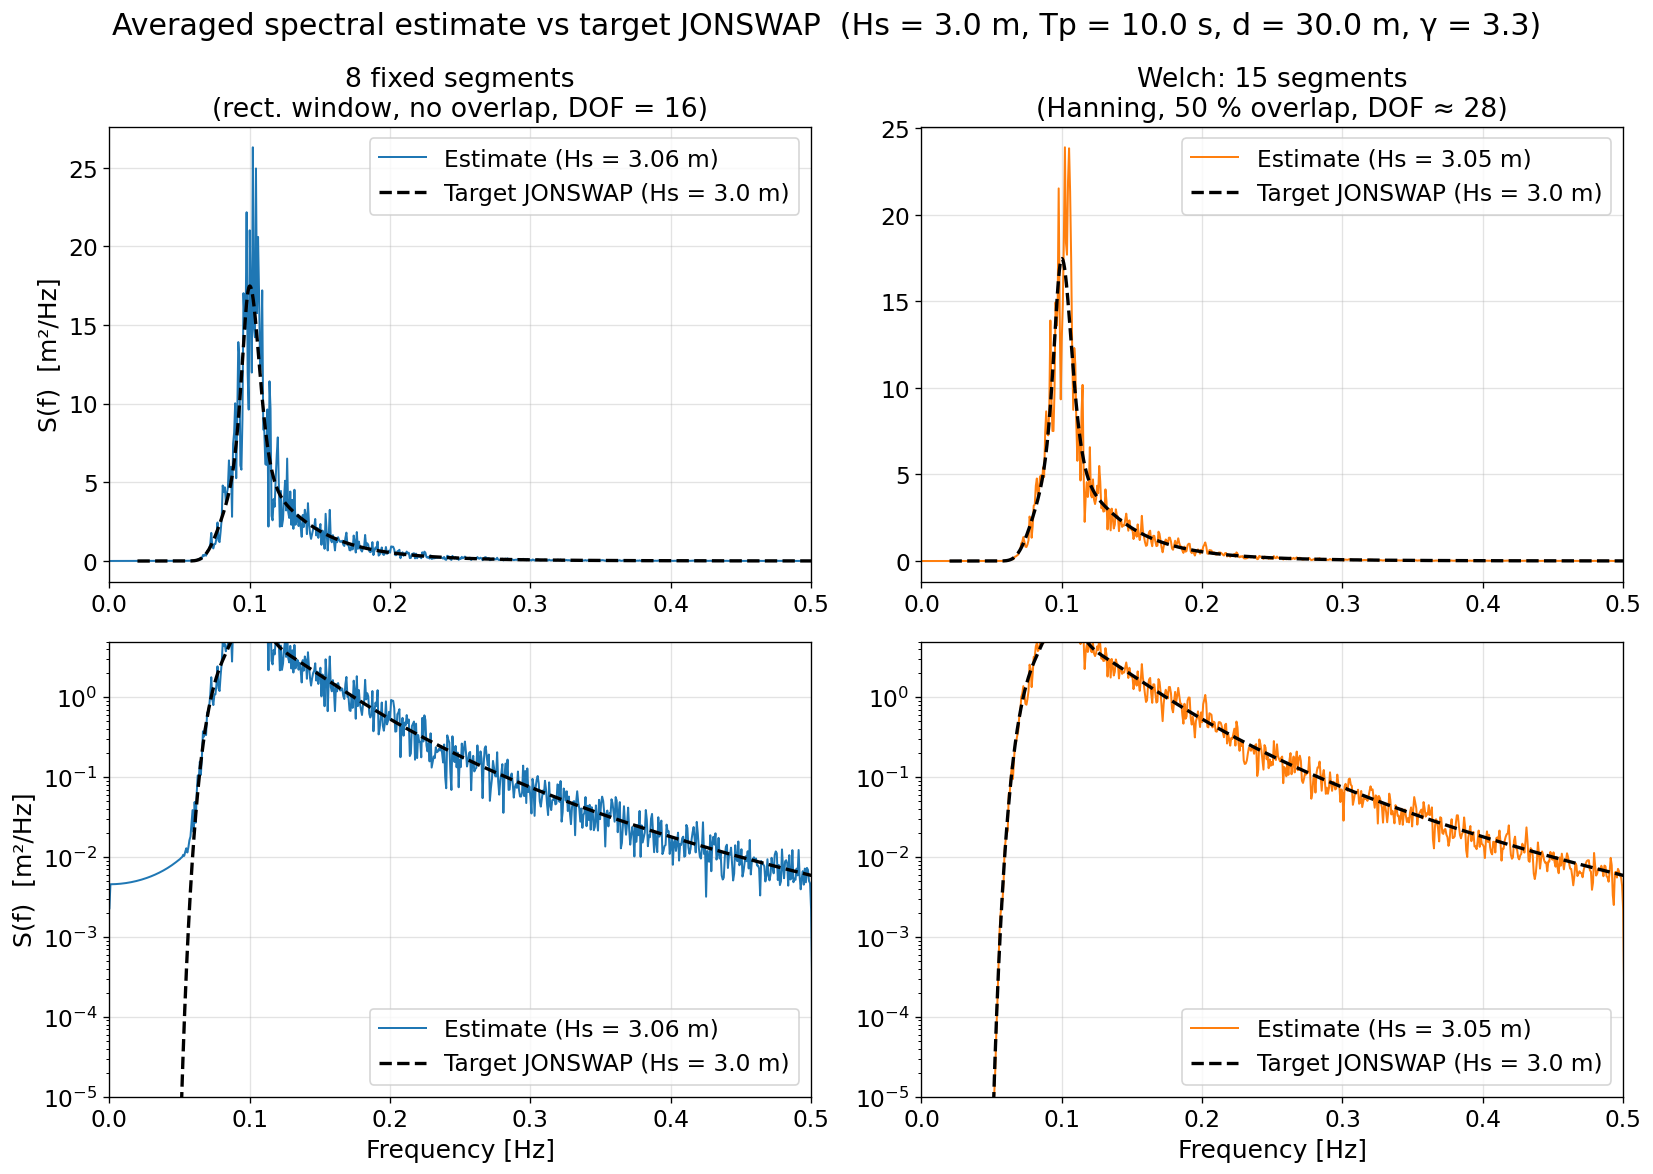

In [12]:
f_fix8, S_fix8 = seg_results[8]
Hs_fix8 = 4 * np.sqrt(np.trapezoid(S_fix8[f_fix8 <= 0.55], f_fix8[f_fix8 <= 0.55]))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col_idx, (f_e, S_e, label, color, Hs_e, n_avg) in enumerate([
    (f_fix8,   S_fix8,   f'8 fixed segments\n(rect. window, no overlap, DOF = 16)',
     'tab:blue',   Hs_fix8,  8),
    (f_welch, S_welch,
     f'Welch: {n_welch} segments\n(Hanning, 50 % overlap, DOF ≈ {int(1.9*n_welch)})',
     'tab:orange', Hs_welch, n_welch),
]):
    for row_idx, yscale in enumerate(['linear', 'log']):
        ax = axes[row_idx][col_idx]
        ax.plot(f_e, S_e, color=color, lw=1.2,
                label=f'Estimate (Hs = {Hs_e:.2f} m)')
        ax.plot(f_ref, S_ref, 'k--', lw=2,
                label=f'Target JONSWAP (Hs = {Hs:.1f} m)')
        ax.set_xlim(0, 0.5)
        ax.set_yscale(yscale)
        if yscale == 'log':
            ax.set_ylim(1e-5, 5)
            ax.set_xlabel('Frequency [Hz]')
        ax.legend()
        if col_idx == 0:
            ax.set_ylabel('S(f)  [m²/Hz]')
        if row_idx == 0:
            ax.set_title(label)

fig.suptitle(
    f'Averaged spectral estimate vs target JONSWAP  '
    f'(Hs = {Hs} m, Tp = {Tp} s, d = {d} m, γ = {gamma})'
)
plt.tight_layout()
fig.savefig('../output/jonswap_welch_comparison.pdf', bbox_inches='tight')
plt.show()

## 9 · Spectral summary statistics

All methods should recover the target **Hs = 4√m₀** and **peak frequency fp = 1/Tp**.

In [13]:
def spectral_stats(f, S, f_max=0.55):
    """Return Hs and peak frequency from a one-sided PSD."""
    mask = (f > 0) & (f <= f_max)
    f_m, S_m = f[mask], S[mask]
    m0  = np.trapezoid(S_m, f_m)
    Hs  = 4 * np.sqrt(m0)
    fp  = f_m[np.argmax(S_m)]
    return Hs, fp

rows = [
    ('Target JONSWAP',              f_ref,    S_ref),
    ('Raw periodogram (1 segment)', f_raw,    S_raw),
    ('4 fixed segments',            *seg_results[4]),
    ('8 fixed segments',            *seg_results[8]),
    ('12 fixed segments',           *seg_results[12]),
    (f'Welch ({n_welch} segments, Hanning 50%)', f_welch, S_welch),
]

print(f"{'Method':<42}  {'Hs [m]':>8}  {'Error':>7}  {'fp [Hz]':>8}  {'Error':>7}")
print('─' * 78)
Hs_tgt, fp_tgt = spectral_stats(f_ref, S_ref)
for label, f_e, S_e in rows:
    Hs_e, fp_e = spectral_stats(f_e, S_e)
    Hs_err = (Hs_e - Hs_tgt) / Hs_tgt * 100
    fp_err = (fp_e - fp_tgt) / fp_tgt * 100
    print(f"{label:<42}  {Hs_e:>8.3f}  {Hs_err:>+6.1f}%  {fp_e:>8.4f}  {fp_err:>+6.1f}%")

print()
print(f"Time-domain check: Hs = 4σ = {4*eta.std():.3f} m  (target {Hs:.1f} m)")
print(f"Component check  : Hs_actual = {wave.actual_hs:.3f} m")

Method                                        Hs [m]    Error   fp [Hz]    Error
──────────────────────────────────────────────────────────────────────────────
Target JONSWAP                                 3.002    +0.0%    0.1001    +0.0%
Raw periodogram (1 segment)                    3.062    +2.0%    0.1033    +3.3%
4 fixed segments                               3.062    +2.0%    0.1022    +2.2%
8 fixed segments                               3.062    +2.0%    0.1022    +2.2%
12 fixed segments                              3.062    +2.0%    0.1044    +4.4%
Welch (15 segments, Hanning 50%)               3.054    +1.7%    0.1022    +2.2%

Time-domain check: Hs = 4σ = 3.062 m  (target 3.0 m)
Component check  : Hs_actual = 3.062 m


## 10 · Discussion

**Why the raw periodogram looks so noisy**  
Each frequency bin of an FFT periodogram follows a $\chi^2_2$ distribution — its standard deviation equals its mean. Averaging *N* independent estimates reduces the standard deviation by $1/\sqrt{N}$, so:

| Segments | DOF | Std / Mean |
|:---:|:---:|:---:|
| 1 | 2 | 100 % |
| 4 | 8 | 50 % |
| 8 | 16 | 35 % |
| 12 | 24 | 29 % |
| Welch (15) | ~28 | 27 % |

**Welch vs fixed-segment**  
Both use the same *segment length* (same Δf), so both see the JONSWAP peak equally clearly. Welch's 50 % overlap roughly doubles the number of segments for free, reducing variance by ~$\sqrt{2}$. The Hanning window also suppresses spectral leakage — visible in the log-scale panel as cleaner tails away from the peak.

**Hs recovery**  
All estimates integrate to the correct Hs because the Rayleigh-drawn component amplitudes are statistically consistent with the target spectrum:  
$m_0 = \sum_i a_i^2/2 \approx \int S(f)\,\mathrm{d}f$, hence $H_s = 4\sqrt{m_0}$.